# Section 1: Basics on deep learning for vision
## 1-ab: Intro to Neural Networks

In [ ]:
import torch
from torch import nn
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import random

In [59]:
training_data = datasets.MNIST(
    root='data', 
    train=True, 
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.MNIST(
    root='data', 
    train=False, 
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

In [61]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

In [62]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

Using mps device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [63]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

In [64]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [65]:
def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [66]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.304897  [   64/60000]
loss: 2.299957  [ 6464/60000]
loss: 2.288202  [12864/60000]
loss: 2.280606  [19264/60000]
loss: 2.281544  [25664/60000]
loss: 2.275188  [32064/60000]
loss: 2.264932  [38464/60000]
loss: 2.261770  [44864/60000]
loss: 2.262615  [51264/60000]
loss: 2.248312  [57664/60000]
Test Error: 
 Accuracy: 22.2%, Avg loss: 2.253313 

Epoch 2
-------------------------------
loss: 2.256756  [   64/60000]
loss: 2.252651  [ 6464/60000]
loss: 2.241664  [12864/60000]
loss: 2.231364  [19264/60000]
loss: 2.232337  [25664/60000]
loss: 2.217513  [32064/60000]
loss: 2.223223  [38464/60000]
loss: 2.205570  [44864/60000]
loss: 2.200384  [51264/60000]
loss: 2.186207  [57664/60000]
Test Error: 
 Accuracy: 54.4%, Avg loss: 2.181510 

Epoch 3
-------------------------------
loss: 2.182278  [   64/60000]
loss: 2.159462  [ 6464/60000]
loss: 2.174613  [12864/60000]
loss: 2.126632  [19264/60000]
loss: 2.144258  [25664/60000]
loss: 2.134152  [32064/600

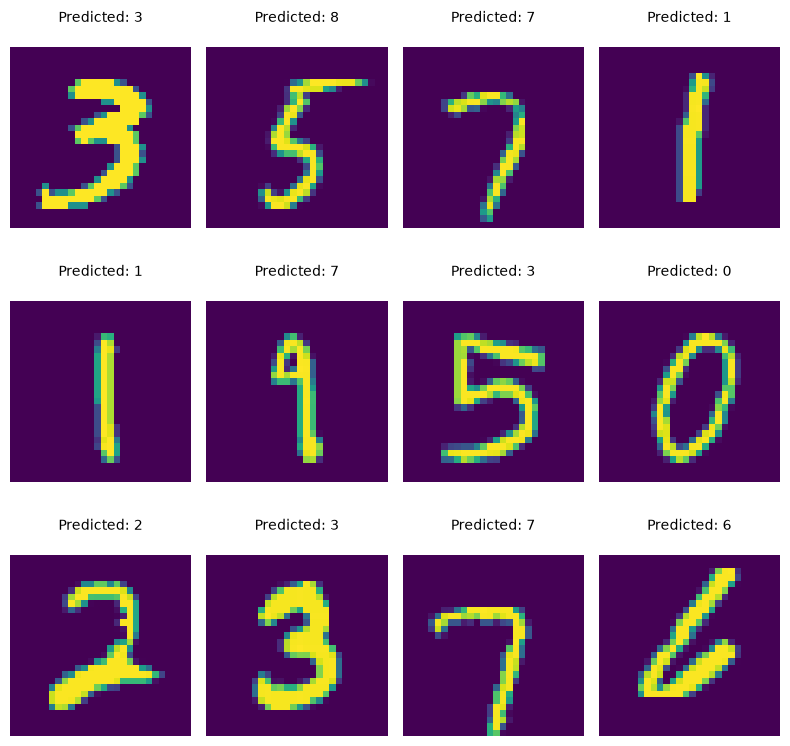

In [ ]:
model.eval()

indices = random.sample(range(len(test_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(8, 8))

with torch.no_grad():
    for i, idx in enumerate(indices):
        x, y = test_data[idx]

        x_input = x.unsqueeze(0).to(device)

        pred = model(x_input)

        predicted = pred[0].argmax(0).item()

        ax = axes[i // 4, i % 4]
        ax.imshow(x.permute(1, 2, 0))

        ax.set_title(
            f'Predicted: {predicted}\n',
            fontsize=10
        )

        ax.axis('off')

plt.tight_layout()
plt.show()